# Gamma/hadron
Simulated gammas against simulated protons: Hillas parameters with the same selection, mean scaled width and length,
reconstructed directions and shower cores, how well cuts separate them, the gammas' energy from a BDT regression, and how well a BDT separates them, from
two already processed sim_telarray productions (run `process_sims.ipynb` on each first).

Everything is set in **Selection** below: pick a config per production, then override its telescopes or selection there to
compare selections. The histograms and profiles are made by the functions in **Plotting**.

Camera coordinates are sim_telarray's, fixed to the alt-az mount: +x towards higher altitude, +y towards lower azimuth.
`distance` and `alpha` are from the camera center (`process_simulation()`'s default `x`, `y`): the source position for
a point-like gamma production without a wobble.

# Imports

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import ks_2samp
from sklearn.ensemble import AdaBoostClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier

from heap import events as ev
from heap.config import local_simulation
from heap import process_simulation as ps
from heap.reconstruction import core_distances, reconstruct_cores, reconstruct_directions, tilted_frame, tilted_positions
from simulation_tools.run_simulation import load_config

# Selection

In [2]:
# one simulation config per production: configs/local.yaml's, or any other, e.g. Path("~/simulations/<name>.yaml")
GAMMA_CONFIG = local_simulation("gamma")
PROTON_CONFIG = local_simulation("proton")
SAMPLES = {"gamma": load_config(GAMMA_CONFIG), "proton": load_config(PROTON_CONFIG)}

# the spectral index each production is weighted to (dN/dE ~ E^index), None = as simulated;
# e.g. -2.7 for cosmic-ray protons, about -3 for the Crab at 10-100 TeV
SPECTRAL_INDEX = {"gamma": None, "proton": None}

# override any of these, e.g. TELESCOPES = ["T1", "T2", "T3"] or IMAGE_CUTS = {"width": ("value", 0.3)}
TELESCOPES = None # None = every telescope; "T<sim_telarray id>"
MIN_TEL = 2
MIN_NPIX = 3
MAX_DISTANCE = 2 # deg, images farther from the camera center are removed
IMAGE_CUTS = {"distance": ("value", MAX_DISTANCE)} # {column: (mode, threshold)}, see heap.events.apply_cut(); "nsigma" thresholds are per production
# events outside these are removed before the BDT, trivially classifiable background
BDT_MSCW_RANGE = (-2, 2)
BDT_MSCL_RANGE = (-2, 5)

# mean scaled width and length: the gammas' width and length in bins of these two columns
LOOKUP_X, LOOKUP_Y = "log10_size", "impact_reco" # or LOOKUP_Y = "distance"
LOOKUP_X_BINS = np.arange(1.5, 5.01, 0.25)
LOOKUP_Y_BINS = np.arange(0, 501, 50) # m; e.g. np.arange(0, 5.01, 0.5) deg for distance

# plotting
ENERGY_BINS = np.logspace(0, 3.6, 19) # TeV, on the simulated histogram's bin edges (every 0.05 in log10)
COLORS = {"gamma": "C0", "proton": "C3"}

# Plotting

In [3]:
# column: (axis label, bin edges)
HILLAS_PARAMS = {
    "N_pix": ("N_pix", np.arange(0.5, 81.5, 2)),
    "log10_size": ("log10 size (ADC)", np.linspace(1, 6, 51)),
    "length": ("length (deg)", np.linspace(0, 2, 51)),
    "width": ("width (deg)", np.linspace(0, 1, 51)),
    "length_width": ("length / width", np.linspace(1, 10, 46)),
    "log10_length_size": ("log10 length / size (deg / ADC)", np.linspace(-5.5, -2, 36)),
    "distance": ("distance (deg)", np.linspace(0, 7, 36)),
    "alpha": ("alpha (deg)", np.linspace(0, 90, 31)),
    "miss": ("miss (deg)", np.linspace(0, 3, 31)),
}
EVENT_PARAMS = { # see event_parameters()
    "n_images": ("images per event", np.arange(0.5, 8.5)),
    "log10_total_size": ("log10 total size (ADC)", np.linspace(1, 6, 41)),
    "log10_SizeSecondMax": ("log10 second largest size (ADC)", np.linspace(1, 6, 41)),
    "max_distance": ("max distance (deg)", np.linspace(0, 7, 36)),
    "MSCW": ("mean scaled width", np.linspace(-2, 5, 57)),
    "MSCL": ("mean scaled length", np.linspace(-2, 5, 57)),
    "theta2": ("theta^2 (deg^2)", np.linspace(0, 4, 41)),
}

def legend_and_title(fig, ax, n_panels, title):
    """the suptitle and ax's legend, shared below the suptitle if there are several panels"""
    if n_panels > 1:
        # constrained layout puts an outside legend over the suptitle, so the legend's title stands in for it
        handles, labels = ax.get_legend_handles_labels()
        fig.legend(handles, labels, loc="outside upper center", ncols=len(labels), fontsize=8, frameon=False,
                   title=title, title_fontsize="large")
    else:
        ax.legend(fontsize=8)
        fig.suptitle(title)

def plot_hists(samples, params, title, n_cols=4):
    """each sample's normalized, weighted histogram, one panel per column of params"""
    n_rows = int(np.ceil(len(params) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (column, (label, bins)) in zip(axs.flat, params.items()):
        for name, sample in samples.items():
            s = sample.dropna(subset=[column])
            ax.hist(s[column], bins, weights=s.weight, density=True, histtype="step", color=COLORS[name], label=f"{name} N={len(s)}")
        ax.set(xlabel=label, ylabel="normalized counts")
    legend_and_title(fig, axs.flat[0], len(params), title)
    for ax in axs.flat[len(params):]:
        ax.axis("off")
    plt.show()

def plot_profiles(samples, profiles, title, n_cols=4, min_entries=10):
    """each sample's weighted mean of y in bins of x, with its error, one panel per (x, y, x bin edges) in profiles"""
    n_rows = int(np.ceil(len(profiles) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4.2*n_cols, 3.6*n_rows), squeeze=False, layout="constrained")
    for ax, (x, y, bins) in zip(axs.flat, profiles):
        centers = (bins[1:] + bins[:-1]) / 2
        for name, sample in samples.items():
            s = sample.dropna(subset=[x, y])
            n, _ = np.histogram(s[x], bins)
            sw, _ = np.histogram(s[x], bins, weights=s.weight)
            with np.errstate(divide="ignore", invalid="ignore"):
                mean = np.histogram(s[x], bins, weights=s.weight * s[y])[0] / sw
                std = np.sqrt(np.clip(np.histogram(s[x], bins, weights=s.weight * s[y]**2)[0] / sw - mean**2, 0, None))
            ok = n >= min_entries
            ax.errorbar(centers[ok], mean[ok], yerr=std[ok] / np.sqrt(n[ok]), fmt="o-", ms=3, color=COLORS[name], label=name)
        ax.set(xlabel=x, ylabel=f"mean {y}")
    legend_and_title(fig, axs.flat[0], len(profiles), title)
    for ax in axs.flat[len(profiles):]:
        ax.axis("off")
    plt.show()

In [4]:
runs, images, showers = {}, {}, {}
for label, cfg in SAMPLES.items():
    runs[label], images[label], showers[label] = ps.load_production(cfg, TELESCOPES)
    header = runs[label].iloc[0]
    # each shower's weight from the simulated power law to SPECTRAL_INDEX, mean 1
    weight = showers[label].energy ** ((SPECTRAL_INDEX[label] or header.spectral_index) - header.spectral_index)
    showers[label]["weight"] = weight / weight.mean()
    print(f"{label}: {cfg['production']['name']} ({cfg['sim_telarray']['tag']}), {len(runs[label])} runs, "
          f"{(runs[label].n_showers * runs[label].n_use).sum()} events simulated")
    print(f"    {header.energy_range[0]:g}-{header.energy_range[1]:g} TeV, index {header.spectral_index:.2g} weighted to "
          f"{SPECTRAL_INDEX[label]}, cores within {header.core_range[1]:g} m, viewcone {header.viewcone[0]:g}-{header.viewcone[1]:g} deg, "
          f"pointing alt {runs[label].alt.mean():.2f}, az {runs[label].az.mean():.2f} deg")
if TELESCOPES is None:
    TELESCOPES = sorted(set(images["gamma"].Telescope) | set(images["proton"].Telescope))
SELECTED = f"≥{MIN_TEL} images per event, ≥{MIN_NPIX} pixels per image" + (f", {IMAGE_CUTS}" if IMAGE_CUTS else "")
print(f"telescopes {TELESCOPES}, selected events: {SELECTED}")

gamma: gamma_pointlike (v1), 1000 runs, 500000 events simulated
    3-1000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-0 deg, pointing alt 70.00, az 191.03 deg
proton: proton_diffuse (v1), 1000 runs, 4000000 events simulated
    6-2000 TeV, index -2.7 weighted to None, cores within 500 m, viewcone 0-8 deg, pointing alt 70.00, az 191.03 deg
telescopes ['T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7'], selected events: ≥2 images per event, ≥3 pixels per image, {'distance': ('value', 2)}


In [5]:
# both productions should be cleaned the same way
pd.DataFrame({
    label: json.loads((ps.processed_path(cfg) / f"{cfg['production']['name']}_processing.json").read_text())
    for label, cfg in SAMPLES.items()
})

,gamma,proton
nsig,5.0,5.0
fit_gaussian,True,True
x,None,None
y,None,None
image_threshold,4.0,4.0
border_threshold,2.0,2.0
keep_brightest_island,True,True


# Events
Each production's images matched into array events by `Run` and `EventID` (`heap.process_simulation.load_events()`),
with their shower's spectral weight and energy, then the selection (`heap.events.apply_cuts()`): at least `MIN_TEL` images per event, `MIN_NPIX` pixels per image, and any `IMAGE_CUTS`. Then each selected event's shower core, from the telescopes' positions in
the plane perpendicular to the pointing (`heap.reconstruction.reconstruct_cores()`), and each image's reconstructed
impact distance (`impact_reco`).

In [6]:
arrays, cores = {}, {}
for label in SAMPLES:
    imgs = images[label].merge(showers[label][["Event", "weight", "energy"]], on="Event")
    imgs["log10_size"] = np.log10(imgs["size"].where(imgs["size"] > 0))
    imgs["length_width"] = imgs.length / imgs.width
    imgs["log10_length_size"] = np.log10(imgs.length / imgs["size"].where(imgs["size"] > 0))
    imgs["log10_energy"] = np.log10(imgs.energy)
    images[label] = imgs
    arrays[label] = ev.apply_cuts(imgs, min_tel=MIN_TEL, min_npix=MIN_NPIX, telescopes=TELESCOPES, cuts=IMAGE_CUTS)
    header, alt, az = runs[label].iloc[0], runs[label].alt.mean(), runs[label].az.mean()
    positions = tilted_positions(arrays[label], {f"T{tel_id}": pos for tel_id, pos in zip(header.tel_id, header.tel_pos)}, *tilted_frame(alt, az))
    cores[label] = reconstruct_cores(arrays[label], positions)
    arrays[label]["impact_reco"] = core_distances(arrays[label], positions, cores[label])
    print(f"{label}: {imgs.Event.nunique()} events ({len(imgs)} images) in all, "
          f"{arrays[label].Event.nunique()} events ({len(arrays[label])} images) selected")

gamma: 29636 events (36728 images) in all, 5238 events (11682 images) selected
proton: 64533 events (76190 images) in all, 697 events (1491 images) selected


## Energy
Each production's simulated, triggered and kept events and effective area (unweighted, see
`heap.process_simulation.plot_energies()`).

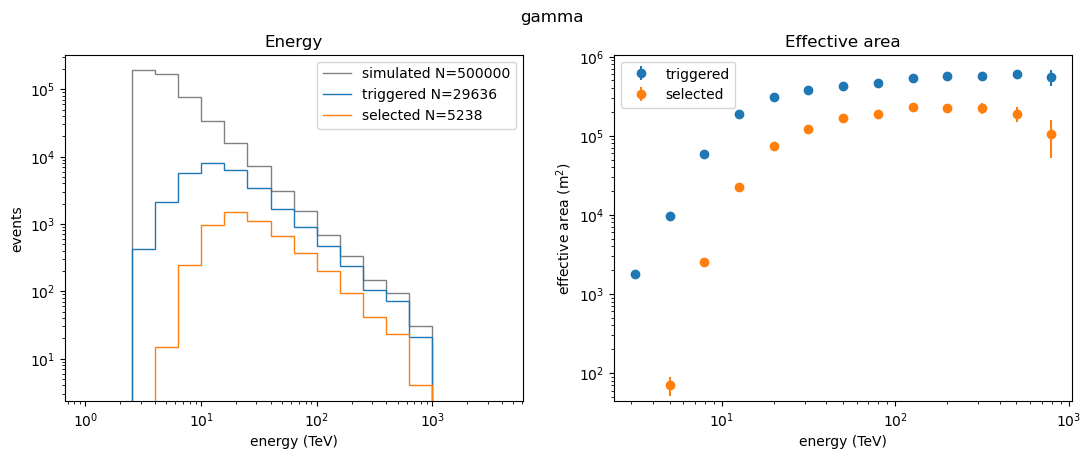

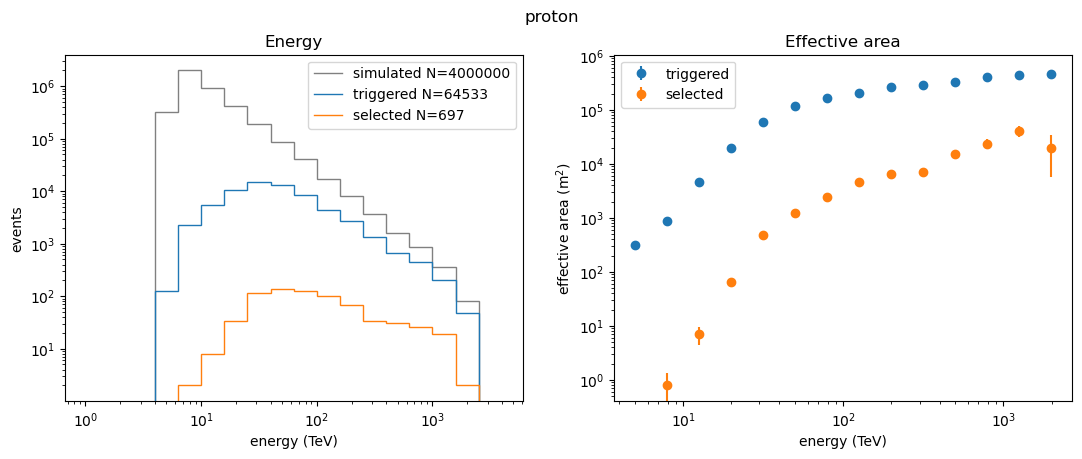

In [7]:
for label in SAMPLES:
    triggered = showers[label][showers[label].Event.isin(images[label].Event)]
    selected = showers[label][showers[label].Event.isin(arrays[label].Event)]
    fig = ps.plot_energies(runs[label], {"triggered": triggered, "selected": selected}, ENERGY_BINS)
    fig.suptitle(label)
    plt.show()

# Hillas parameters
Normalized histograms of every image, weighted by its shower's spectral weight.

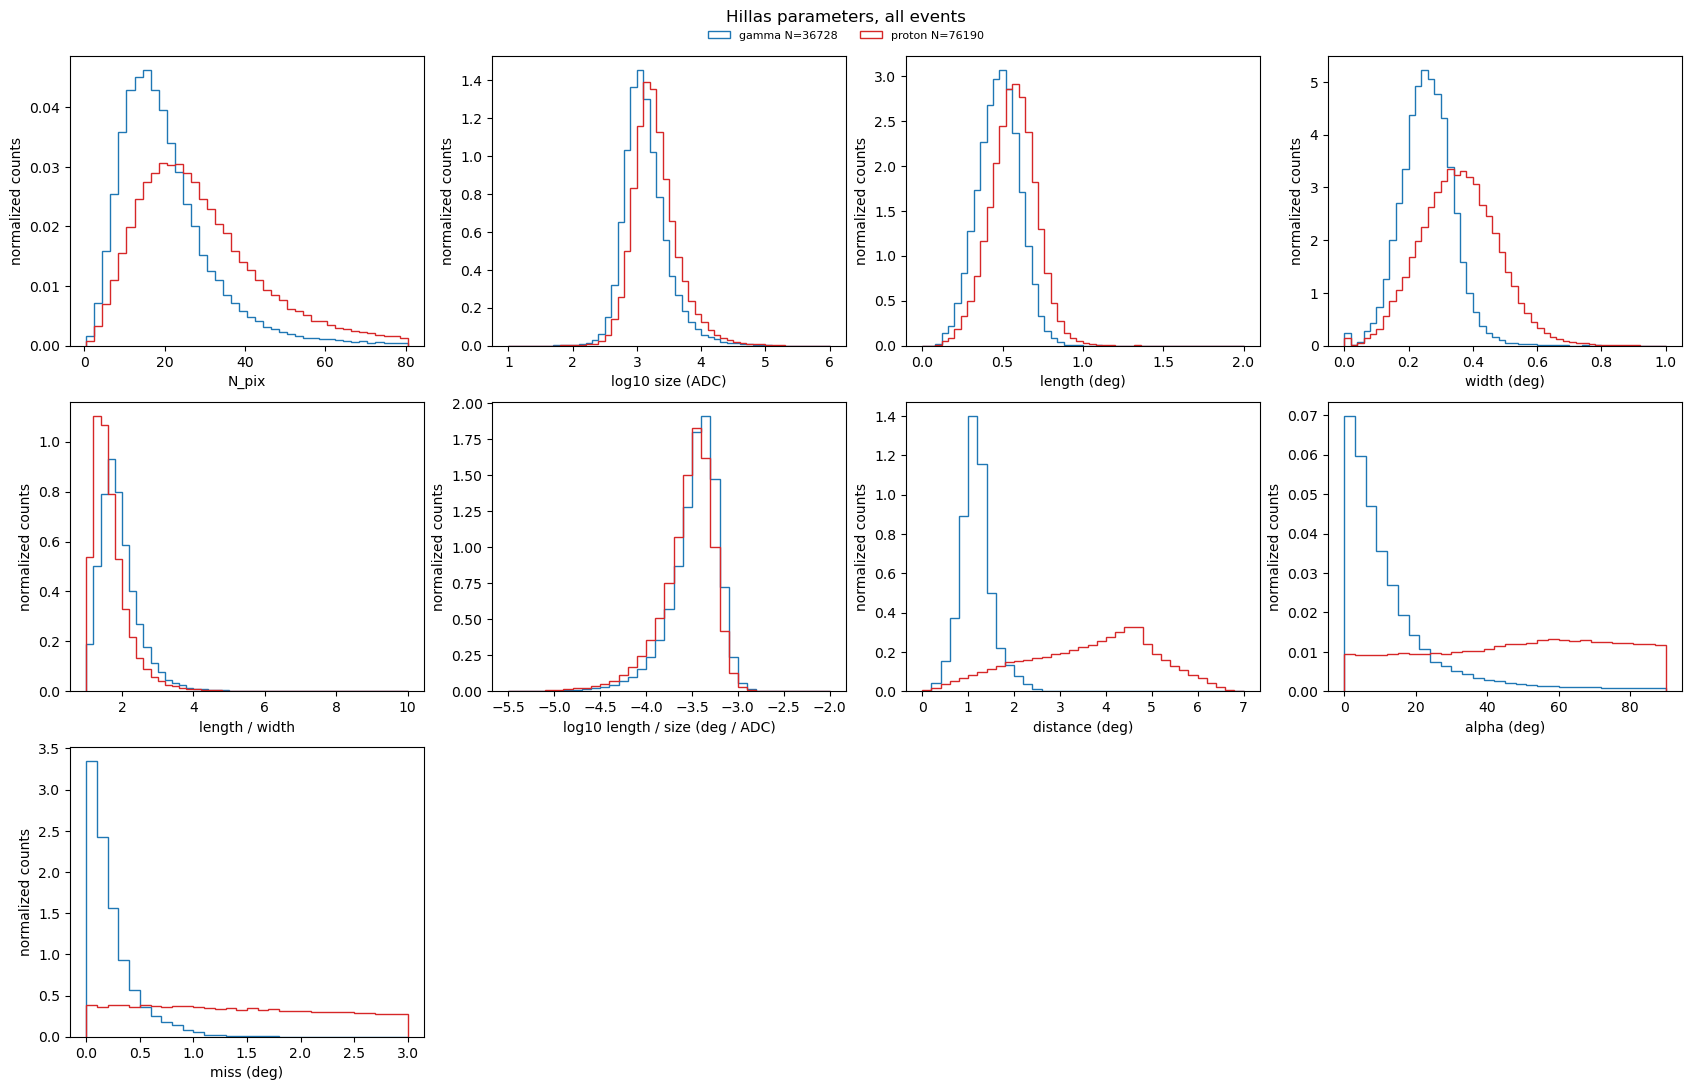

In [8]:
plot_hists(images, HILLAS_PARAMS, "Hillas parameters, all events")

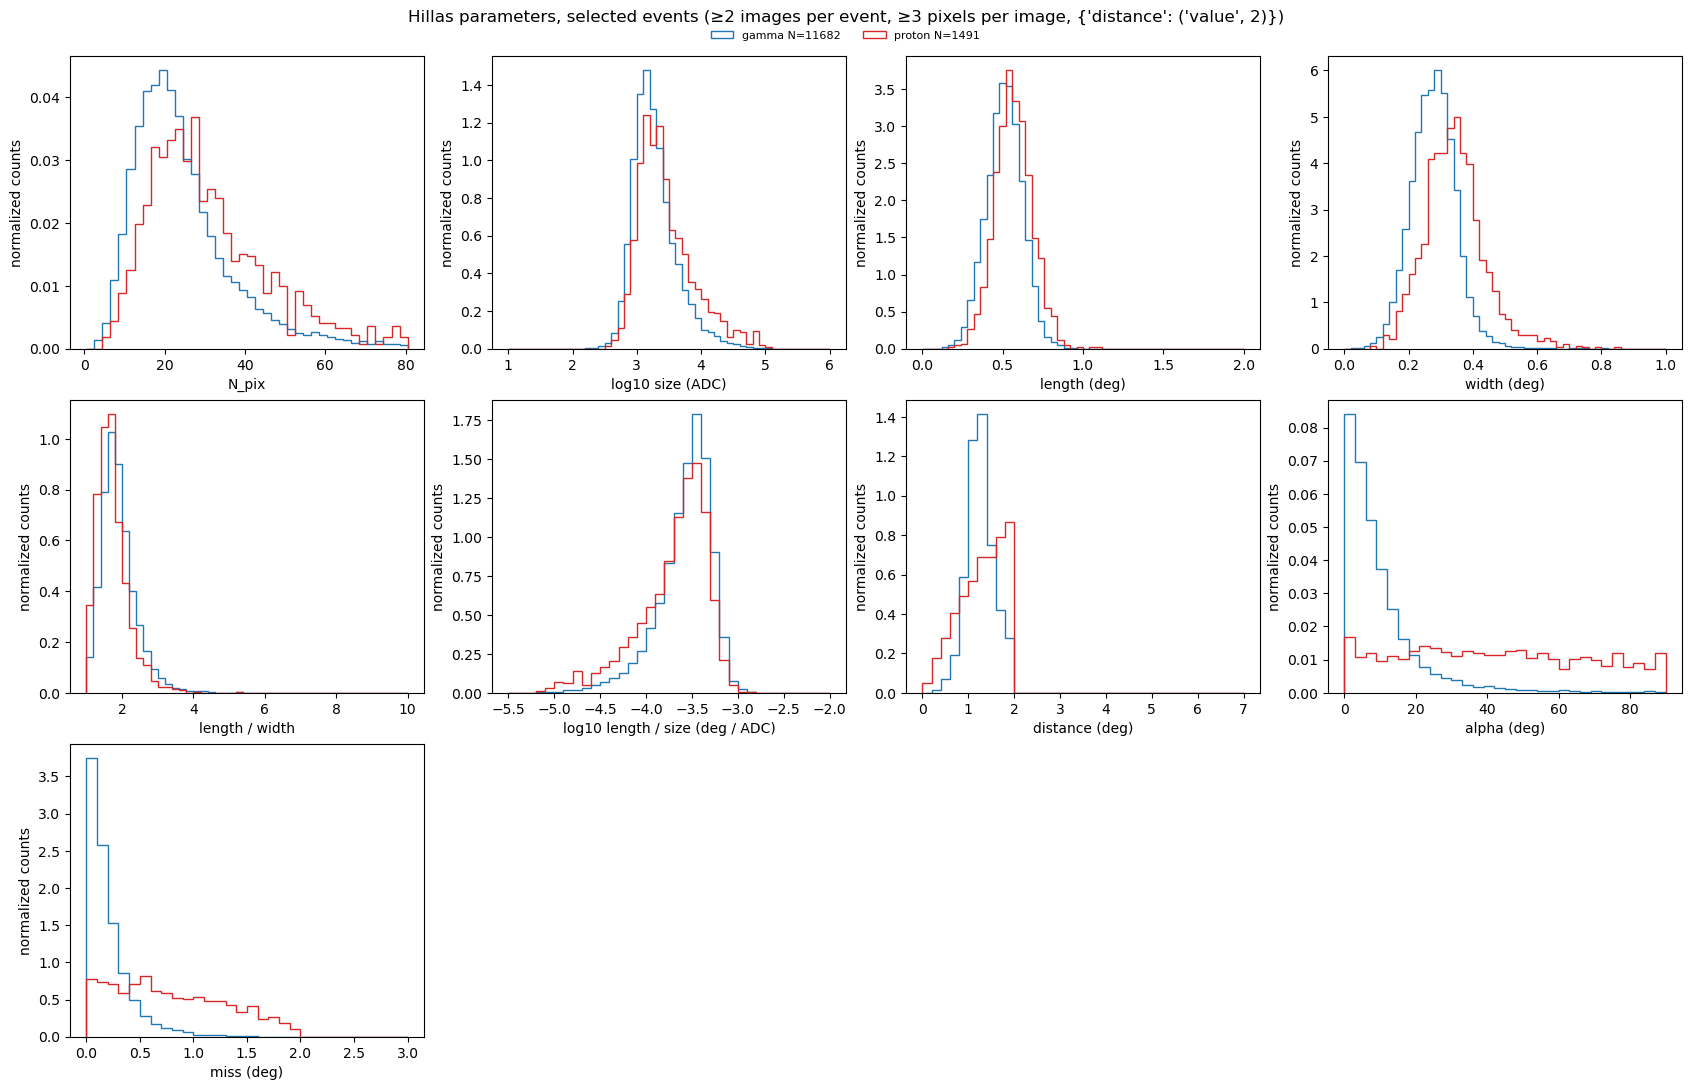

In [9]:
plot_hists(arrays, HILLAS_PARAMS, f"Hillas parameters, selected events ({SELECTED})")

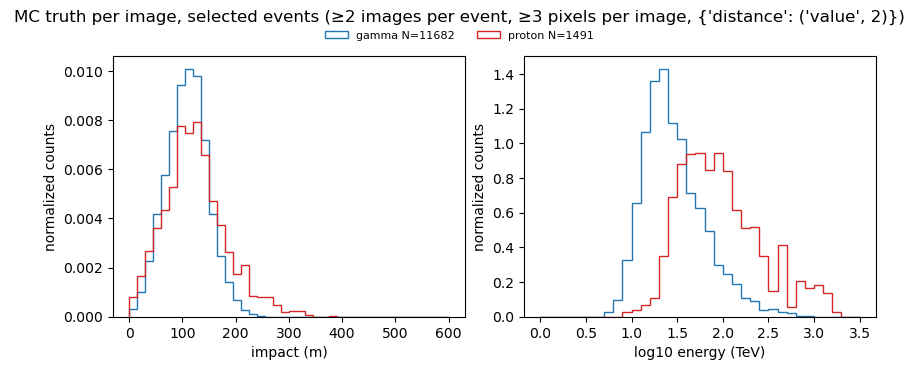

In [10]:
plot_hists(arrays, {
    "impact": ("impact (m)", np.linspace(0, 600, 41)),
    "log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36)),
}, f"MC truth per image, selected events ({SELECTED})", n_cols=2)

In [11]:
pd.concat({label: array[["N_pix", "size", "length", "width", "length_width", "distance", "alpha", "impact_reco"]].describe() for label, array in arrays.items()}, axis=1)

gamma                                                           \
              N_pix           size        length         width  length_width   
count  11682.000000   11682.000000  11682.000000  11682.000000  11682.000000   
mean      25.379045    2893.169895      0.510767      0.277680      1.910149   
std       15.799135    5142.908731      0.111469      0.069124      0.506485   
min        3.000000      88.103776      0.096209      0.032687      1.011222   
25%       16.000000    1103.304327      0.437828      0.231731      1.579424   
50%       22.000000    1643.009801      0.512037      0.278100      1.825808   
75%       30.000000    2794.601758      0.585966      0.321252      2.137105   
max      296.000000  178221.682645      0.958147      0.807469      8.253421   

                                                      proton                 \
           distance         alpha   impact_reco        N_pix           size   
count  11682.000000  11682.000000  11682.000000  1491.000000    1491.000000   
mean       1.263872     10.180286    190.741637    38.240778    5565.505635   
std        0.299129     11.854213   1495.783725    29.415178   10546.205522   
min        0.219314      0.000101      0.029942     5.000000     336.398373   
25%        1.071937      2.974592     80.243912    21.000000    1389.818061   
50%        1.248196      6.636748    118.209812    29.000000    2266.449014   
75%        1.436474     12.774615    155.012795    44.000000    4670.742279   
max        1.999739     89.841823  91707.128680   249.000000  102434.448370   

                                                                        \
            length        width length_width     distance        alpha   
count  1491.000000  1491.000000  1491.000000  1491.000000  1491.000000   
mean      0.565875     0.342715     1.727610     1.297138    42.337956   
std       0.115521     0.095085     0.440171     0.475950    25.616795   
min       0.189569     0.088375     1.013435     0.074700     0.128928   
25%       0.489856     0.280573     1.428854     0.948955    21.123534   
50%       0.562410     0.337631     1.655891     1.358110    41.115780   
75%       0.640048     0.392229     1.922634     1.702026    63.807039   
max       1.091184     0.845171     5.394080     1.999908    89.945800   

                    
       impact_reco  
count  1491.000000  
mean    177.609637  
std     280.064443  
min       0.067058  
25%      87.113114  
50%     135.602847  
75%     184.616596  
max    5205.866484

## Profiles
Mean of one parameter in bins of another for the selected events, with its error.

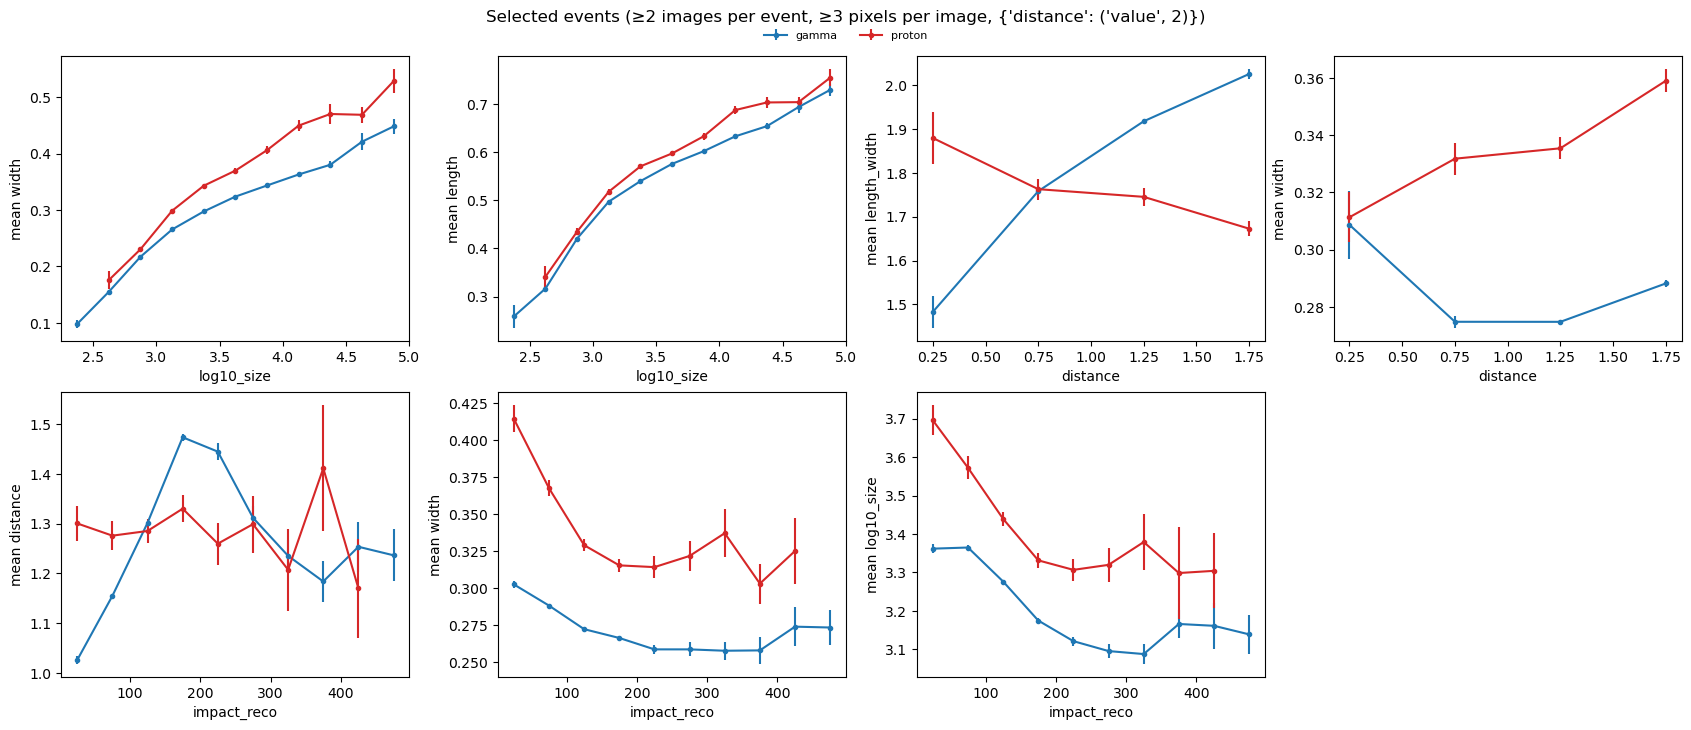

In [12]:
PROFILES = [ # (x, y, x bin edges): mean y in bins of x
    ("log10_size", "width", np.linspace(1.5, 5, 15)),
    ("log10_size", "length", np.linspace(1.5, 5, 15)),
    ("distance", "length_width", np.linspace(0, 5, 11)),
    ("distance", "width", np.linspace(0, 5, 11)),
    ("impact_reco", "distance", np.linspace(0, 500, 11)),
    ("impact_reco", "width", np.linspace(0, 500, 11)),
    ("impact_reco", "log10_size", np.linspace(0, 500, 11)),
]
plot_profiles(arrays, PROFILES, f"Selected events ({SELECTED})")

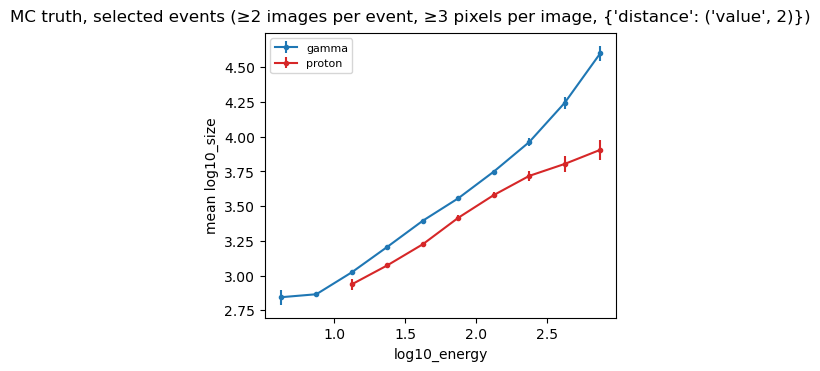

In [13]:
plot_profiles(arrays, [("log10_energy", "log10_size", np.linspace(0.5, 3, 11))], f"MC truth, selected events ({SELECTED})", n_cols=1)

# Mean scaled width and length
Lookup tables of the gammas' weighted median and sigma (its 84% - 16% range, twice a Gaussian's sigma) of width and length per bin of `LOOKUP_X` and `LOOKUP_Y`, interpolated between bin centers. `MSCWT` and `MSCWTSigma` are each image's expected width and its sigma from the tables, and its `scaled_width` is (width - `MSCWT`) / `MSCWTSigma`. Each event's mean scaled width, `MSCW`, is the mean of its images' `scaled_width` weighted by (`MSCWT` / `MSCWTSigma`)²; the same for length (`MSCLT`, `MSCLTSigma`, `scaled_length`, `MSCL`). Images outside the tables (or in bins with too few gammas) are left out. The gammas' values are out-of-fold: each quarter of their events uses tables of the other three quarters, so none is scaled by tables it helped make; the protons' use the tables of every gamma, which are the ones shown.

In [14]:
def lookup_bins(images):
    """each image's (LOOKUP_X, LOOKUP_Y) bin, -1 outside LOOKUP_X_BINS, LOOKUP_Y_BINS"""
    return pd.DataFrame({
        "xi": pd.cut(images[LOOKUP_X], LOOKUP_X_BINS, labels=False).fillna(-1).astype(int),
        "yi": pd.cut(images[LOOKUP_Y], LOOKUP_Y_BINS, labels=False).fillna(-1).astype(int),
    })

def lookup_table(images, column, min_images=10):
    """weighted median of column and sigma, its 84% - 16% range, per (LOOKUP_X, LOOKUP_Y) bin with at least min_images images"""
    images = pd.concat([images[[column, "weight"]], lookup_bins(images)], axis=1).dropna()
    images = images[(images.xi >= 0) & (images.yi >= 0)]
    def quantiles(group):
        group = group.sort_values(column)
        low, median, high = np.interp([0.16, 0.5, 0.84], group.weight.cumsum() / group.weight.sum(), group[column])
        return pd.Series({"median": median, "sigma": high - low, "n": len(group)})
    table = images.groupby(["xi", "yi"])[[column, "weight"]].apply(quantiles)
    return table[table.n >= min_images]

def interpolate_between(value1, center1, value2, center2, x):
    """linear interpolation between two bins; with one NaN, the other bin's value if x is closer to it, else NaN"""
    fraction1 = 1 - (x - center1) / (center2 - center1)
    both = fraction1 * value1 + (1 - fraction1) * value2
    both = np.where(np.isnan(value2) & (fraction1 > 0.5), value1, both)
    return np.where(np.isnan(value1) & (fraction1 < 0.5), value2, both)

def from_table(images, table, key):
    """each image's key of table, interpolated between bin centers, first in LOOKUP_Y and then LOOKUP_X; NaN outside it"""
    n_x, n_y = len(LOOKUP_X_BINS) - 1, len(LOOKUP_Y_BINS) - 1
    grid = np.pad(table[key].unstack().reindex(index=range(n_x), columns=range(n_y)).to_numpy(dtype=float), 1, constant_values=np.nan) # bin i is grid[i + 1]
    x_centers = (LOOKUP_X_BINS[1:] + LOOKUP_X_BINS[:-1]) / 2
    y_centers = (LOOKUP_Y_BINS[1:] + LOOKUP_Y_BINS[:-1]) / 2
    x_centers = np.r_[2*x_centers[0] - x_centers[1], x_centers, 2*x_centers[-1] - x_centers[-2]]
    y_centers = np.r_[2*y_centers[0] - y_centers[1], y_centers, 2*y_centers[-1] - y_centers[-2]]
    bins = lookup_bins(images)
    xi, yi = bins.xi.to_numpy(), bins.yi.to_numpy()
    x, y = images[LOOKUP_X].to_numpy(), images[LOOKUP_Y].to_numpy()
    inside = (xi >= 0) & (yi >= 0)
    # the bins below each image's center: bin - 1 if it is below its bin's center
    i = np.where(inside, xi + 1 - (x < x_centers[np.where(inside, xi + 1, 0)]), 0)
    j = np.where(inside, yi + 1 - (y < y_centers[np.where(inside, yi + 1, 0)]), 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        in_y = [interpolate_between(grid[i + k, j], y_centers[j], grid[i + k, j + 1], y_centers[j + 1], y) for k in (0, 1)]
        values = interpolate_between(in_y[0], x_centers[i], in_y[1], x_centers[i + 1], x)
    # no interpolation in the last bins
    last = inside & ((xi == n_x - 1) | (yi == n_y - 1))
    values[last] = grid[xi[last] + 1, yi[last] + 1]
    values[~inside] = np.nan
    return values

def out_of_fold_expected(column):
    """{label: (each image's expected column and sigma)}, the gammas' from tables of the other events' gammas, the protons' from tables of every gamma"""
    gamma_images = arrays["gamma"]
    expected, sigma = np.full(len(gamma_images), np.nan), np.full(len(gamma_images), np.nan)
    for fit, apply in GroupKFold(4).split(gamma_images, groups=gamma_images.Event):
        table = lookup_table(gamma_images.iloc[fit], column)
        expected[apply], sigma[apply] = from_table(gamma_images.iloc[apply], table, "median"), from_table(gamma_images.iloc[apply], table, "sigma")
    protons = arrays["proton"]
    return {"gamma": (expected, sigma), "proton": (from_table(protons, tables[column], "median"), from_table(protons, tables[column], "sigma"))}

def scale(array, column, expected, sigma):
    """(array's column - expected) / sigma, and each image's weight (expected / sigma)^2; NaN without a positive expected and sigma"""
    good = (expected > 0) & (sigma > 0)
    expected, sigma = np.where(good, expected, np.nan), np.where(good, sigma, np.nan)
    return (array[column].to_numpy() - expected) / sigma, (expected / sigma)**2

def mean_scaled(array, scaled, weight):
    """per event, the mean of its images' scaled values weighted by weight"""
    return (array[scaled] * array[weight]).groupby(array.Event).sum() / array[weight].groupby(array.Event).sum()

def event_parameters(array):
    """
    one row per event: n_images, log10_total_size (of its images' summed size), log10_SizeSecondMax (of its second
    largest image), max_distance (of its farthest image), weight, and MSCW, MSCL: the means of its images' scaled_width and
    scaled_length, each weighted by (expected / sigma)^2 (images outside the lookup tables left out, NaN if all are)
    """
    grouped = array.groupby("Event")
    return pd.DataFrame({
        "n_images": grouped.size(),
        "log10_total_size": np.log10(grouped["size"].sum()),
        "log10_SizeSecondMax": np.log10(grouped["size"].apply(lambda size: size.nlargest(2).iloc[-1])),
        "max_distance": grouped.distance.max(),
        "MSCW": mean_scaled(array, "scaled_width", "width_weight"),
        "MSCL": mean_scaled(array, "scaled_length", "length_weight"),
        "weight": grouped.weight.first(),
    })

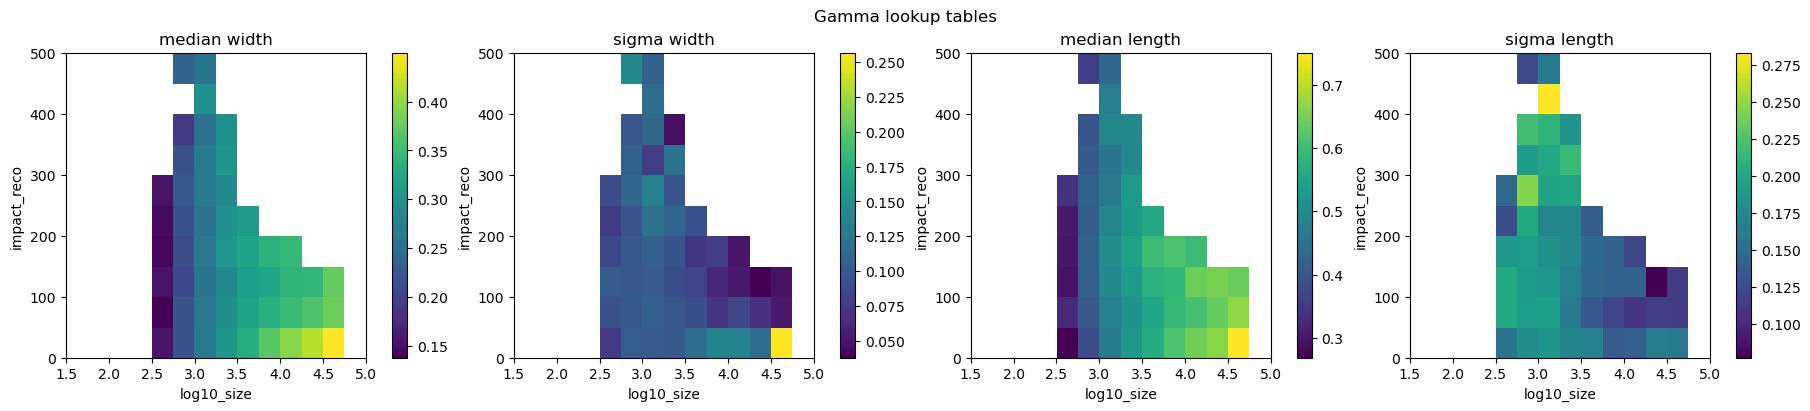

In [15]:
tables = {column: lookup_table(arrays["gamma"], column) for column in ["width", "length"]}
for column, prefix in {"width": "MSCW", "length": "MSCL"}.items():
    expected = out_of_fold_expected(column)
    for label, array in arrays.items():
        array[f"{prefix}T"], array[f"{prefix}TSigma"] = expected[label]
        array[f"scaled_{column}"], array[f"{column}_weight"] = scale(array, column, *expected[label])

fig, axs = plt.subplots(1, 4, figsize=(18, 4), layout="constrained")
for ax, (column, key) in zip(axs, [(column, key) for column in tables for key in ("median", "sigma")]):
    grid = tables[column][key].unstack().reindex(index=range(len(LOOKUP_X_BINS) - 1), columns=range(len(LOOKUP_Y_BINS) - 1))
    im = ax.imshow(grid.T, origin="lower", aspect="auto", extent=[LOOKUP_X_BINS[0], LOOKUP_X_BINS[-1], LOOKUP_Y_BINS[0], LOOKUP_Y_BINS[-1]])
    fig.colorbar(im, ax=ax)
    ax.set(xlabel=LOOKUP_X, ylabel=LOOKUP_Y, title=f"{key} {column}")
fig.suptitle("Gamma lookup tables")
plt.show()

# Reconstruction
Arrival directions (`heap.reconstruction`), and their θ² to the source: the gammas' mean true direction (`true_x`,
`true_y`, see `heap.process_simulation.camera_position()`). Each event's mean reconstructed impact distance (`mean_impact_reco`), and
`core_error`, the distance from the true core in the plane perpendicular to the pointing (`heap.process_simulation.tilted_core()`).

In [16]:
SOURCE_X, SOURCE_Y = showers["gamma"].true_x.mean(), showers["gamma"].true_y.mean()
print(f"source at ({SOURCE_X:.3f}, {SOURCE_Y:.3f}) deg, gammas' true directions within "
      f"{np.hypot(showers['gamma'].true_x - SOURCE_X, showers['gamma'].true_y - SOURCE_Y).max():.2f} deg of it")

events = {}
for label, array in arrays.items():
    e = event_parameters(array).join(showers[label].set_index("Event")[["energy"]])
    e["log10_energy"] = np.log10(e.energy)
    e = e.join(reconstruct_directions(array).set_index("Event")[["Xoffset", "Yoffset"]])
    e["theta2"] = (e.Xoffset - SOURCE_X)**2 + (e.Yoffset - SOURCE_Y)**2
    e = e.join(cores[label].set_index("Event")).join(array.groupby("Event").impact_reco.mean().rename("mean_impact_reco"))
    true_x, true_y = ps.tilted_core(showers[label].set_index("Event").loc[e.index], runs[label].alt.mean(), runs[label].az.mean())
    e["core_error"] = np.hypot(e.core_x - true_x, e.core_y - true_y)
    events[label] = e
    print(f"{label}: {len(e)} events, {e.theta2.notna().sum()} directions and {e.core_x.notna().sum()} cores reconstructed, "
          f"core error median {e.core_error.median():.0f} m")

source at (-0.000, 0.000) deg, gammas' true directions within 0.00 deg of it
gamma: 5238 events, 5238 directions and 5238 cores reconstructed, core error median 31 m
proton: 697 events, 697 directions and 697 cores reconstructed, core error median 39 m


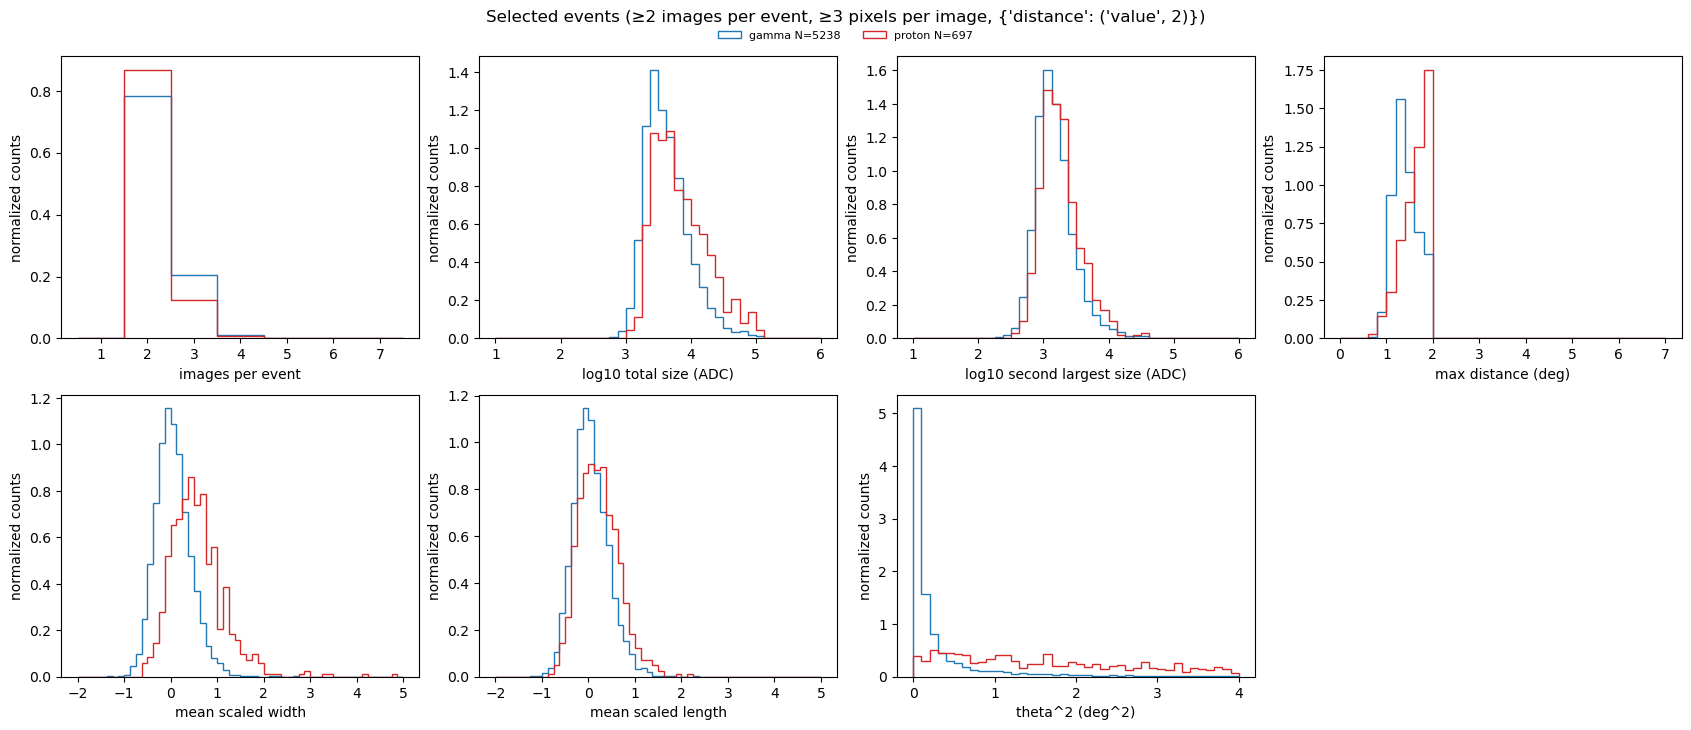

In [17]:
plot_hists(events, EVENT_PARAMS, f"Selected events ({SELECTED})")

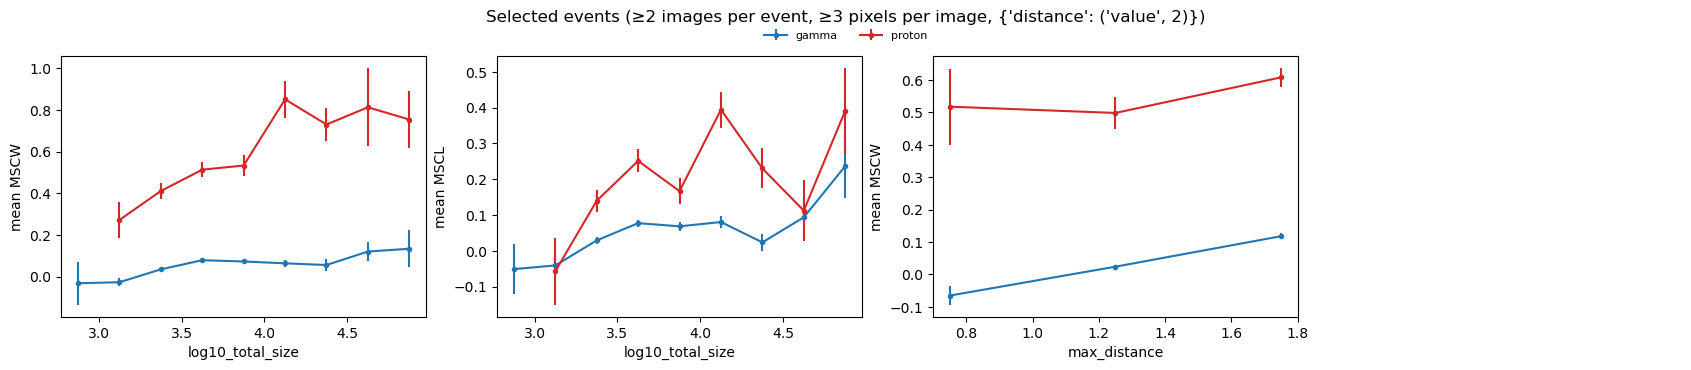

In [18]:
plot_profiles(events, [
    ("log10_total_size", "MSCW", np.linspace(2.5, 5.5, 13)),
    ("log10_total_size", "MSCL", np.linspace(2.5, 5.5, 13)),
    ("max_distance", "MSCW", np.linspace(0, 5, 11)),
], f"Selected events ({SELECTED})")

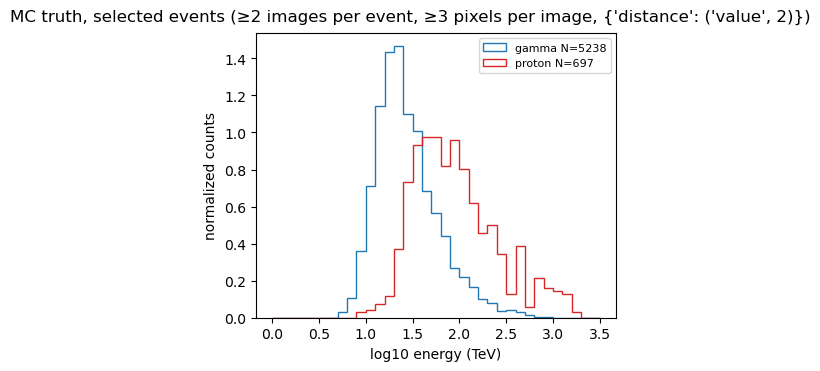

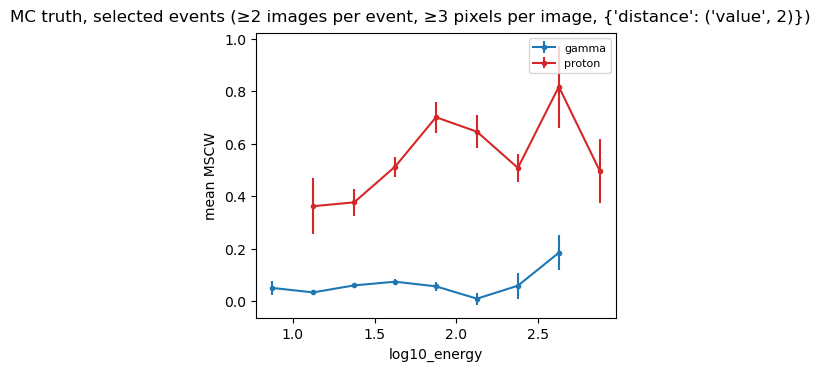

In [19]:
plot_hists(events, {"log10_energy": ("log10 energy (TeV)", np.linspace(0, 3.5, 36))}, f"MC truth, selected events ({SELECTED})", n_cols=1)
plot_profiles(events, [("log10_energy", "MSCW", np.linspace(0.5, 3, 11))], f"MC truth, selected events ({SELECTED})", n_cols=1)

## Cores
Each image's reconstructed against true impact distance, and the core error's 68% containment per bin of true energy.
Near-parallel image axes (mostly two-image events) put a few cores kilometres away.

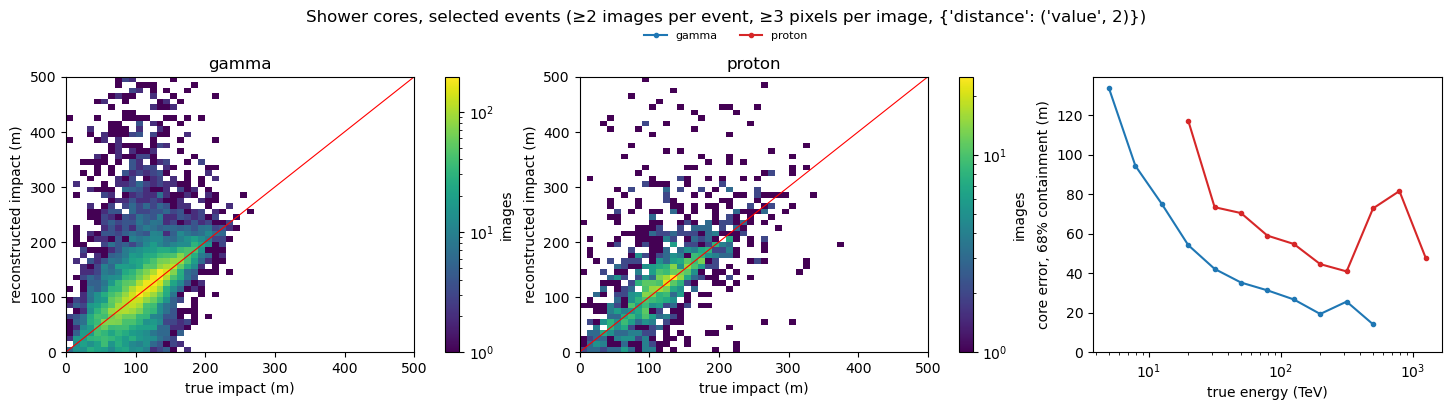

In [20]:
fig, axs = plt.subplots(1, len(arrays) + 1, figsize=(4.8*(len(arrays) + 1), 4), squeeze=False, layout="constrained")
impact_bins = np.linspace(0, 500, 51)
for ax, (label, array) in zip(axs[0], arrays.items()):
    *_, im = ax.hist2d(array.impact, array.impact_reco, bins=impact_bins, norm=LogNorm())
    fig.colorbar(im, ax=ax, label="images")
    ax.plot(impact_bins[[0, -1]], impact_bins[[0, -1]], "r-", lw=0.8)
    ax.set(xlabel="true impact (m)", ylabel="reconstructed impact (m)", title=label)
ax = axs[0, -1]
centers = np.sqrt(ENERGY_BINS[1:] * ENERGY_BINS[:-1])
for label, e in events.items():
    grouped = e.core_error.groupby(pd.cut(e.energy, ENERGY_BINS), observed=False)
    containment = grouped.quantile(0.68).where(grouped.size() >= 10)
    ax.plot(centers, containment.to_numpy(), "o-", ms=3, color=COLORS[label], label=label)
ax.set(xscale="log", ylim=(0, None), xlabel="true energy (TeV)", ylabel="core error, 68% containment (m)")
legend_and_title(fig, ax, axs.size, f"Shower cores, selected events ({SELECTED})")
plt.show()

# Cuts
How well a single cut separates the gammas from the protons: each one's weighted fraction kept against the cut, and
the quality factor Q = (gammas kept) / sqrt(protons kept), the significance's improvement for a background-dominated
source, with the best cut that keeps at least 10% of the gammas. Fractions are of the events with a value: events
without a mean scaled width (all their images outside the lookup table) are left out of its scan.

`theta2`, `max_distance`, `alpha` and `miss` separate by direction (point-like gammas against diffuse protons),
`MSCW`, `MSCL`, `width` and `length` by shape.

In [21]:
def cut_efficiencies(gammas, protons, column, keep="below", n_cuts=200):
    """the weighted fraction of the gammas and protons with a value of column that a cut on it keeps, and Q"""
    gammas, protons = gammas.dropna(subset=[column]), protons.dropna(subset=[column])
    cuts = np.unique(np.quantile(pd.concat([gammas[column], protons[column]]), np.linspace(0.001, 0.999, n_cuts)))
    def kept(sample):
        values = sample[column].to_numpy()[None, :]
        passed = values < cuts[:, None] if keep == "below" else values > cuts[:, None]
        return (passed * sample.weight.to_numpy()).sum(axis=1) / sample.weight.sum()
    eff = pd.DataFrame({"cut": cuts, "gamma": kept(gammas), "proton": kept(protons)})
    with np.errstate(divide="ignore"):
        eff["Q"] = eff.gamma / np.sqrt(eff.proton)
    return eff

def plot_cut_scan(gammas, protons, cuts, title="", min_gamma=0.1):
    """
    cut_efficiencies() of each column of cuts ({column: (keep, plotted range)}); returns the best cut on each, the one
    with the highest Q among those keeping at least min_gamma of the gammas
    """
    fig, axs = plt.subplots(1, len(cuts), figsize=(4.5*len(cuts), 3.8), squeeze=False, layout="constrained")
    best = {}
    for ax, (column, (keep, lim)) in zip(axs[0], cuts.items()):
        eff = cut_efficiencies(gammas, protons, column, keep)
        ok = eff[(eff.gamma >= min_gamma) & (eff.proton > 0)]
        best[column] = {"keep": keep} | ok.loc[ok.Q.idxmax()].to_dict()
        ax.plot(eff.cut, eff.gamma, color=COLORS["gamma"], label="gammas kept")
        ax.plot(eff.cut, eff.proton, color=COLORS["proton"], label="protons kept")
        ax.axvline(best[column]["cut"], color="grey", ls=":")
        q_ax = ax.twinx()
        q_ax.plot(eff.cut, eff.Q, "k--")
        q_ax.set(ylabel="Q (dashed)", ylim=(0, None))
        ax.set(xlabel=column, ylabel="fraction kept", xlim=lim, ylim=(0, 1.02), title=f"keep {keep}")
    legend_and_title(fig, axs[0, 0], len(cuts), title)
    plt.show()
    return pd.DataFrame(best).T

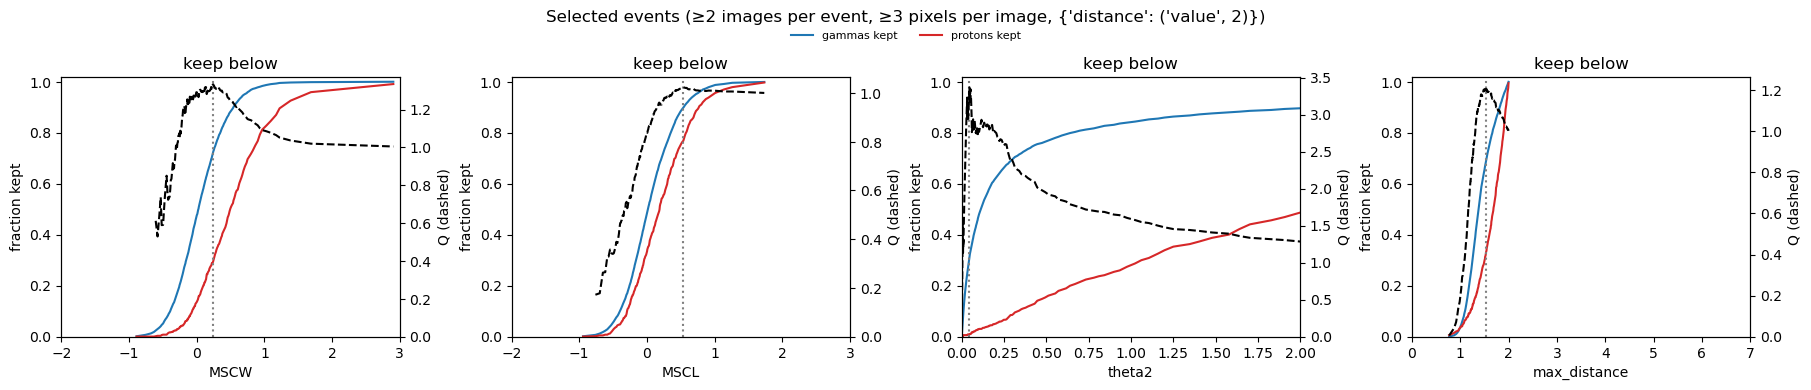

,keep,cut,gamma,proton,Q
MSCW,below,0.241053,0.722375,0.293495,1.333407
MSCL,below,0.538493,0.898545,0.768533,1.024964
theta2,below,0.045605,0.312524,0.008608,3.368402
max_distance,below,1.542759,0.700649,0.337159,1.206655


In [22]:
EVENT_CUTS = { # column: (keep, plotted range)
    "MSCW": ("below", (-2, 3)),
    "MSCL": ("below", (-2, 3)),
    "theta2": ("below", (0, 2)),
    "max_distance": ("below", (0, 7)),
}
plot_cut_scan(events["gamma"], events["proton"], EVENT_CUTS, f"Selected events ({SELECTED})")

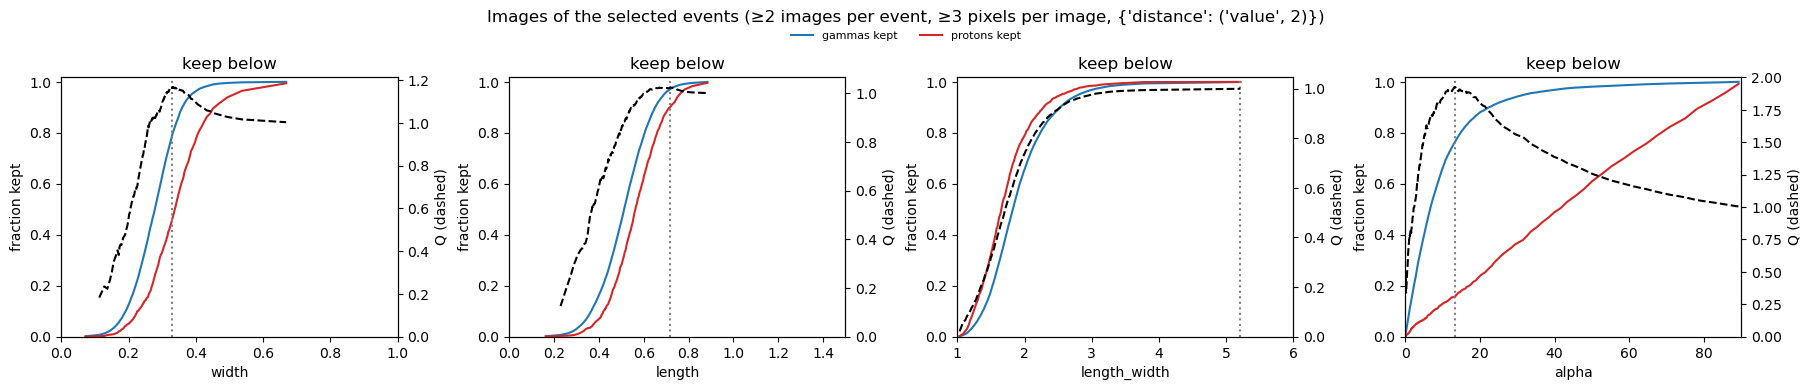

,keep,cut,gamma,proton,Q
width,below,0.329585,0.790704,0.459423,1.166561
length,below,0.718541,0.971923,0.900738,1.024077
length_width,below,5.211012,0.998887,0.999329,0.999222
alpha,below,13.216258,0.761599,0.156271,1.926581


In [23]:
# per image instead of per event
IMAGE_CUT_SCAN = { # column: (keep, plotted range)
    "width": ("below", (0, 1)),
    "length": ("below", (0, 1.5)),
    "length_width": ("below", (1, 6)),
    "alpha": ("below", (0, 90)),
}
plot_cut_scan(arrays["gamma"], arrays["proton"], IMAGE_CUT_SCAN, f"Images of the selected events ({SELECTED})")

In [24]:
# a combination of cuts, as a pandas query on the events; events without a value (NaN) fail it
SELECTION = "MSCW < 0.5 and theta2 < 0.2"
kept = {label: e.query(SELECTION).weight.sum() / e.weight.sum() for label, e in events.items()}
print(f"{SELECTION}: {kept['gamma']:.1%} of gammas, {kept['proton']:.2%} of protons kept, Q = {kept['gamma'] / np.sqrt(kept['proton']):.2f}")

MSCW < 0.5 and theta2 < 0.2: 56.3% of gammas, 3.01% of protons kept, Q = 3.24


# Energy
A gradient-boosted regression (`sklearn.ensemble.HistGradientBoostingRegressor`) of each image's log10 true energy from
`ENERGY_FEATURES`, all of which the data also has, trained on the gammas. Each event's energy is the size-weighted mean of its
telescopes' log10 energies, and its energy χ² (`chi2_energy`) their scatter around that mean. The gammas' energies are
out-of-fold: each quarter of the events is predicted by a model trained on the other three quarters, so none saw its own
event; the protons' are from a model trained on every gamma. The direction
(`distance`) is left out, so that `chi2_energy` doesn't bring it into the BDT.

Per bin of true energy, the bias is the median of E_reco / E_true - 1 and the resolution half its 16-84% range.

In [25]:
ENERGY_FEATURES = ["log10_size", "impact_reco", "N_pix", "width", "length"]

gamma_images = arrays["gamma"]
regressor = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=0)
image_energy = {"gamma": cross_val_predict(regressor, gamma_images[ENERGY_FEATURES], gamma_images.log10_energy, groups=gamma_images.Event, cv=GroupKFold(4))}
image_energy["proton"] = regressor.fit(gamma_images[ENERGY_FEATURES], gamma_images.log10_energy).predict(arrays["proton"][ENERGY_FEATURES])
resolution = (image_energy["gamma"] - gamma_images.log10_energy).std()
print(f"{len(gamma_images)} gamma images of {gamma_images.Event.nunique()} events, one telescope's log10 energy resolution: {resolution:.3f}")

for label, array in arrays.items():
    size_sum = array["size"].groupby(array.Event).transform("sum")
    mean = (array["size"] * image_energy[label]).groupby(array.Event).transform("sum") / size_sum
    squares = ((image_energy[label] - mean) / resolution)**2
    events[label]["log10_energy_reco"] = mean.groupby(array.Event).first()
    events[label]["chi2_energy"] = squares.groupby(array.Event).sum() / (array.groupby("Event").size() - 1)

11682 gamma images of 5238 events, one telescope's log10 energy resolution: 0.189


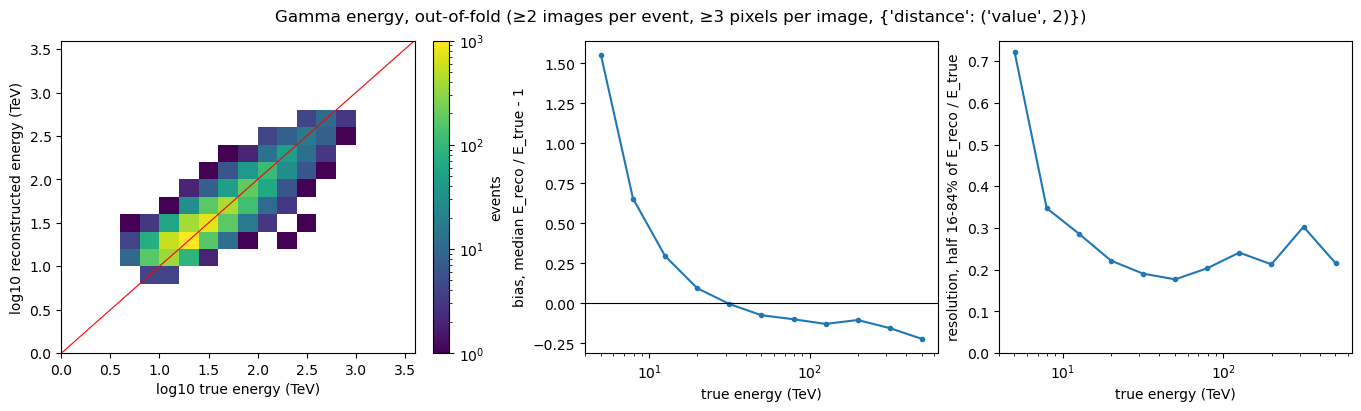

In [26]:
def bias_resolution(e_true, e_reco, bins, min_entries=10):
    """per bin of e_true: the median of e_reco / e_true - 1 (bias) and half its 16-84% range (resolution), NaN under min_entries"""
    grouped = (e_reco / e_true - 1).groupby(pd.cut(e_true, bins), observed=False)
    q = grouped.quantile([0.16, 0.5, 0.84]).unstack()
    result = pd.DataFrame({"bias": q[0.5], "resolution": (q[0.84] - q[0.16]) / 2})
    result[grouped.size() < min_entries] = np.nan
    return result.reset_index(drop=True)

log_bins = np.log10(ENERGY_BINS)
centers = np.sqrt(ENERGY_BINS[1:] * ENERGY_BINS[:-1])
energy_reco = 10**events["gamma"].log10_energy_reco
br = bias_resolution(events["gamma"].energy, energy_reco, ENERGY_BINS)
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4), layout="constrained")
*_, im = axs[0].hist2d(events["gamma"].log10_energy, events["gamma"].log10_energy_reco, bins=log_bins, norm=LogNorm())
fig.colorbar(im, ax=axs[0], label="events")
axs[0].plot(log_bins[[0, -1]], log_bins[[0, -1]], "r-", lw=0.8)
axs[0].set(xlabel="log10 true energy (TeV)", ylabel="log10 reconstructed energy (TeV)")
axs[1].plot(centers, br.bias, "o-", ms=3)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set(xscale="log", xlabel="true energy (TeV)", ylabel="bias, median E_reco / E_true - 1")
axs[2].plot(centers, br.resolution, "o-", ms=3)
axs[2].set(xscale="log", ylim=(0, None), xlabel="true energy (TeV)", ylabel="resolution, half 16-84% of E_reco / E_true")
fig.suptitle(f"Gamma energy, out-of-fold ({SELECTED})")
plt.show()

In [27]:
# feature importance: how much the R² of held-out events' images drops when one feature is shuffled
train_events, test_events = train_test_split(gamma_images.Event.unique(), test_size=0.25, random_state=0)
e_train, e_test = gamma_images[gamma_images.Event.isin(train_events)], gamma_images[gamma_images.Event.isin(test_events)]
regressor.fit(e_train[ENERGY_FEATURES], e_train.log10_energy)
importance = permutation_importance(regressor, e_test[ENERGY_FEATURES], e_test.log10_energy, n_repeats=10, random_state=0)
pd.DataFrame({"R² drop": importance.importances_mean, "std": importance.importances_std}, index=ENERGY_FEATURES).sort_values("R² drop", ascending=False)

,R² drop,std
log10_size,1.522400,0.032236
impact_reco,0.282593,0.009620
width,0.015433,0.004544
N_pix,0.011483,0.002692
length,0.006177,0.003823


## Energy χ²
The scatter of the telescopes' log10 energies around their size-weighted mean, in units of one telescope's resolution.

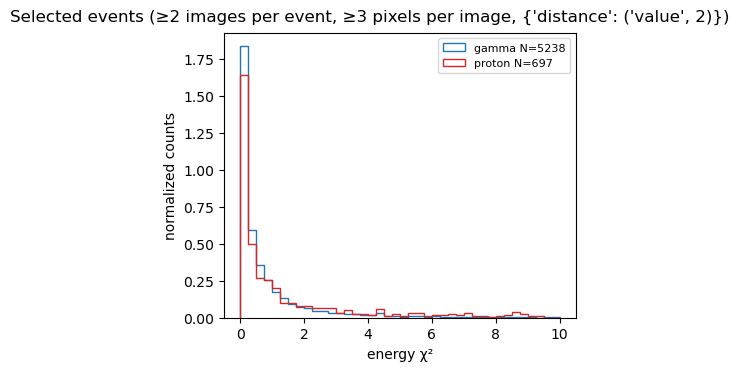

In [28]:
plot_hists(events, {"chi2_energy": ("energy χ²", np.linspace(0, 10, 41))}, f"Selected events ({SELECTED})", n_cols=1)

# BDT
AdaBoost on decision trees with the Gini index (`sklearn.ensemble.AdaBoostClassifier`) separating gammas from protons, with
100 trees of depth up to 2, a learning rate of 0.1 and at least 100 events per leaf, shallow to avoid overtraining with few protons. Trained per image, whichever telescope it came from, on `FEATURES`: each image's `scaled_width`, `scaled_length` (see **Mean scaled width and length**) and `impact_reco`, and its event's `chi2_energy` and `log10_SizeSecondMax`. Images outside the lookup tables are `OUTSIDE_TABLES`, since AdaBoost takes no NaN.

Events with `MSCW` outside `BDT_MSCW_RANGE` or `MSCL` outside `BDT_MSCL_RANGE`, or with no image in the lookup tables, are removed first. The rest are split 3:1 into training and test, keeping each event's images together. Each event's score is the mean of its images' decision function, scaled so that the training images span 0 (most proton-like) to 1 (most gamma-like); `BOUNDARY` is the score of decision function 0. Each production's spectral weights are scaled so both sum to 1. The direction (`distance`, `theta2` and `max_distance`, which mostly tell point-like gammas from diffuse protons) is left out, to stay a separate cut, and images far from the camera center are removed before everything else, by `IMAGE_CUTS`.

In [29]:
IMAGE_FEATURES = ["scaled_width", "scaled_length", "impact_reco"] # or width, length, N_pix, log10_size, ...
EVENT_FEATURES = ["chi2_energy", "log10_SizeSecondMax"]
FEATURES = IMAGE_FEATURES + EVENT_FEATURES
OUTSIDE_TABLES = -999

bdt_images = pd.concat([
    array.assign(label=label).merge(events[label][EVENT_FEATURES], left_on="Event", right_index=True)
    for label, array in arrays.items()
], ignore_index=True)
bdt_images[FEATURES] = bdt_images[FEATURES].fillna(OUTSIDE_TABLES)
bdt_images["is_gamma"] = (bdt_images.label == "gamma").astype(int)

X = pd.concat(events, names=["label"]).reset_index()
n_selected = X.groupby("label").size()
X = X[X.MSCW.between(*BDT_MSCW_RANGE) & X.MSCL.between(*BDT_MSCL_RANGE)].copy()
print("preselected events: " + ", ".join(f"{label} {n} of {n_selected[label]}" for label, n in X.groupby("label").size().items()))
X["is_gamma"] = (X.label == "gamma").astype(int)
X["class_weight"] = X.weight / X.groupby("label").weight.transform("sum")
train, test = train_test_split(X, test_size=0.25, stratify=X.is_gamma, random_state=0)

def images_of(events):
    """the bdt_images of these events, with each production's weights scaled to sum to 1"""
    images = bdt_images.merge(events[["label", "Event"]], on=["label", "Event"])
    return images.assign(class_weight=images.weight / images.groupby("label").weight.transform("sum"))

train_images, test_images = images_of(train), images_of(test)
tree = DecisionTreeClassifier(criterion="gini", splitter="best", max_depth=2, min_samples_leaf=100, random_state=0)
bdt = AdaBoostClassifier(estimator=tree, n_estimators=100, learning_rate=0.1, random_state=0)
bdt.fit(train_images[FEATURES], train_images.is_gamma, sample_weight=train_images.class_weight)

train_decision = bdt.decision_function(train_images[FEATURES])
decision_range = train_decision.min(), train_decision.max()
BOUNDARY = -decision_range[0] / (decision_range[1] - decision_range[0])

def with_scores(events, images):
    """events with score: the mean of its images' decision function, scaled to the training images' range"""
    scores = ((bdt.decision_function(images[FEATURES]) - decision_range[0]) / (decision_range[1] - decision_range[0])).clip(0, 1)
    return events.merge(images.assign(score=scores).groupby(["label", "Event"], as_index=False).score.mean(), on=["label", "Event"])

train, test = with_scores(train, train_images), with_scores(test, test_images)
gammas, protons = test[test.is_gamma == 1], test[test.is_gamma == 0]
# overtraining: the training and test scores of each class should agree
ks = {label: ks_2samp(train.score[train.label == label], test.score[test.label == label]).pvalue for label in SAMPLES}
print(f"{len(train)} training events ({len(train_images)} images), {len(test)} test events, "
      f"train AUC {roc_auc_score(train.is_gamma, train.score, sample_weight=train.class_weight):.3f}, "
      f"test AUC {roc_auc_score(test.is_gamma, test.score, sample_weight=test.class_weight):.3f}, "
      f"train vs test KS p-values " + ", ".join(f"{label} {p:.2f}" for label, p in ks.items()))

preselected events: gamma 5083 of 5238, proton 650 of 697
4299 training events (9564 images), 1434 test events, train AUC 0.811, test AUC 0.807, train vs test KS p-values gamma 0.02, proton 0.51


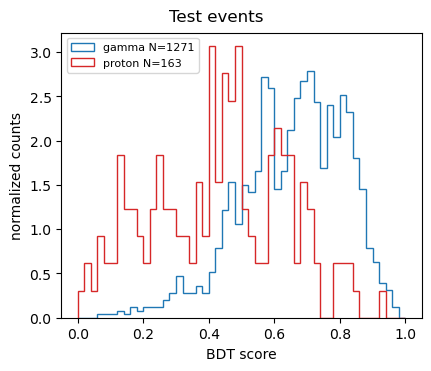

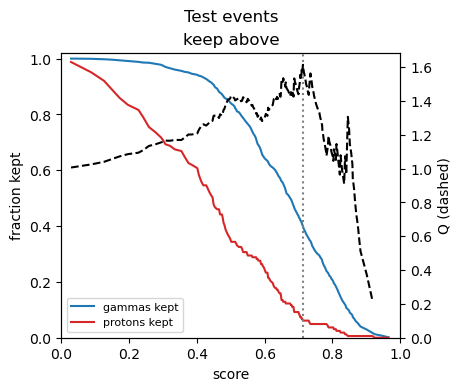

,keep,cut,gamma,proton,Q
score,above,0.712725,0.399685,0.06135,1.61366


In [30]:
plot_hists({"gamma": gammas, "proton": protons}, {"score": ("BDT score", np.linspace(0, 1, 51))}, "Test events", n_cols=1)
plot_cut_scan(gammas, protons, {"score": ("above", (0, 1))}, "Test events")

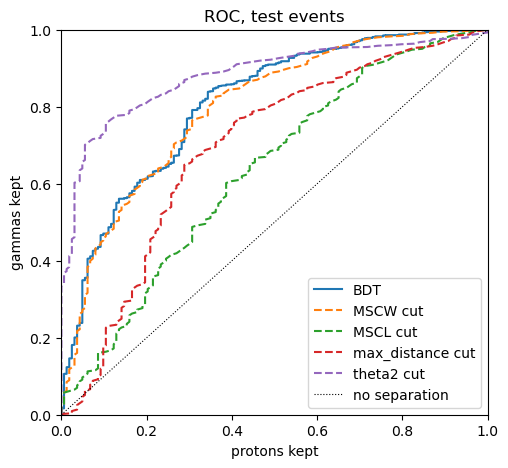

In [31]:
fpr, tpr, _ = roc_curve(test.is_gamma, test.score, sample_weight=test.class_weight)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, label="BDT")
for column in ["MSCW", "MSCL", "max_distance", "theta2"]: # single cuts, for comparison
    eff = cut_efficiencies(gammas, protons, column)
    ax.plot(eff.proton, eff.gamma, ls="--", label=f"{column} cut")
ax.plot([0, 1], [0, 1], "k:", lw=0.8, label="no separation")
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="protons kept", ylabel="gammas kept", title="ROC, test events")
ax.legend()
plt.show()

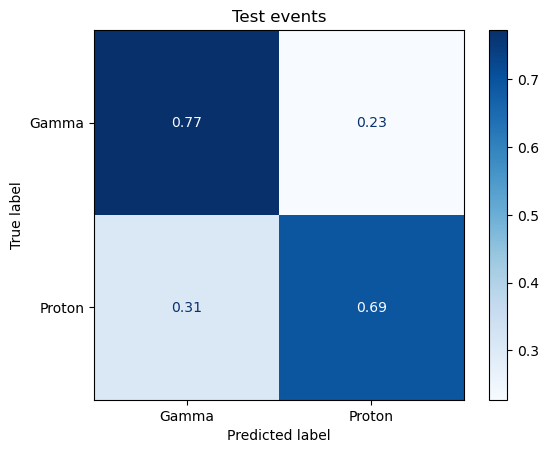

In [32]:
# confusion matrix at the BDT's own boundary (decision function 0), each row normalized to its true class
ConfusionMatrixDisplay.from_predictions(test.is_gamma, (test.score > BOUNDARY).astype(int), labels=[1, 0], sample_weight=test.class_weight,
                                        display_labels=["Gamma", "Proton"], cmap=plt.cm.Blues, normalize="true")
plt.title("Test events")
plt.show()

In [33]:
# feature importance: how much the test images' AUC drops when one feature is shuffled
importance = permutation_importance(bdt, test_images[FEATURES], test_images.is_gamma, sample_weight=test_images.class_weight,
                                    scoring="roc_auc", n_repeats=10, random_state=0)
pd.DataFrame({"AUC drop": importance.importances_mean, "std": importance.importances_std}, index=FEATURES).sort_values("AUC drop", ascending=False)

,AUC drop,std
scaled_width,0.131214,0.012812
chi2_energy,0.036963,0.003528
impact_reco,0.026276,0.005211
log10_SizeSecondMax,0.011506,0.004484
scaled_length,0.005168,0.001270
